# CoAtNet — Marrying Convolution and Attention

**Paper:** Z. Dai, H. Liu, Q. V. Le, and M. Tan,
"CoAtNet: Marrying Convolution and Attention for All Data Sizes,"
in *Advances in Neural Information Processing Systems (NeurIPS)*, 2021, vol. 34, pp. 3965–3977.
arXiv: [2106.04803](https://arxiv.org/abs/2106.04803)

> **One-line summary:** A 5-stage staged hybrid network that uses depthwise convolution
> in early stages (local inductive bias) and relative self-attention in later stages
> (global context), outperforming both pure CNNs and ViT on most data regimes.


> 📄 **Paper:** Dai, Liu, Le & Tan (2021). CoAtNet: Marrying Convolution and Attention for All Data Sizes. NeurIPS 2021.
> 🔗 **Link:** <https://arxiv.org/abs/2106.04803>
> 🧩 **Implementation:** `hale_core/nn/vision/hybrid/coatnet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> S0["S0 stem: 2 × conv 3×3 /2 → 64 (paper)"]:::stage
  S0 --> S1["S1: MBConv ×2 → 96 /4"]:::stage --> S2["S2: MBConv ×3 → 192 /8"]:::stage
  S2 --> S3["S3: Transformer (rel-attn) ×5 → 384 /16"]:::stage --> S4["S4: Transformer ×2 → 768 /32"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph REL["relative attention"]
    direction LR
    Q["x_i"] --> SC["softmax_j( x_iᵀx_j + w_(i−j) )"]:::block --> Y["Σ_j a_ij x_j"]:::block
  end
  S3 -.-> REL
  C["C-C-T-T layout: convolution for early, attention for late stages"]:::block -.-> S1
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Pipeline (ASCII)

```
Input Image [B, 3, 224, 224]
        │
        ▼
┌───────────────────────────────────────────────────────────────┐
│  S0: Conv Stem  (2 × stride-2 Conv3×3, BN, GELU)             │
│  [B, 64, 56, 56]   pure convolution — builds low-level feats  │
└───────────────────────────────────┬───────────────────────────┘
                                    │ stride-2
┌───────────────────────────────────▼───────────────────────────┐
│  S1: MBConv Blocks  depth=2      [B, 96,  28, 28]             │
│  BN pre-norm → expand 4× → depthwise → SE → project → residual│
└───────────────────────────────────┬───────────────────────────┘
                                    │ stride-2
┌───────────────────────────────────▼───────────────────────────┐
│  S2: MBConv Blocks  depth=3      [B, 192, 14, 14]             │
│  Same as S1, deeper — still conv-dominated features            │
└───────────────────────────────────┬───────────────────────────┘
                     ─── conv→attention transition ───
                                    │ stride-2
┌───────────────────────────────────▼───────────────────────────┐
│  S3: RelAttn Blocks  depth=5     [B, 384,  7,  7]             │
│  Pre-LN → MHSA (+ 2D rel bias) → Pre-LN → FFN                 │
└───────────────────────────────────┬───────────────────────────┘
                                    │ stride-2
┌───────────────────────────────────▼───────────────────────────┐
│  S4: RelAttn Blocks  depth=2     [B, 768,  4,  4]             │
│  Global self-attention with relative position bias             │
└───────────────────────────────────┬───────────────────────────┘
                                    │
                            Global Avg Pool
                                    │
                          pooled_output [B, 768]

─────────────────────────────────────────────────────────────────
 MBConv Block                     RelAttn Block
─────────────────────────────────────────────────────────────────
 x → BN → expand 1×1 → GELU      x → LN → Q K V Linear
       → dw-Conv3×3  → GELU            → Q·K/√d + rel_bias
       → SE (pool + 2FC)               → softmax → · V
       → project 1×1                 → + residual
       → DropPath                  x → LN → FFN (4× expand)
       → + residual                   → + residual
```


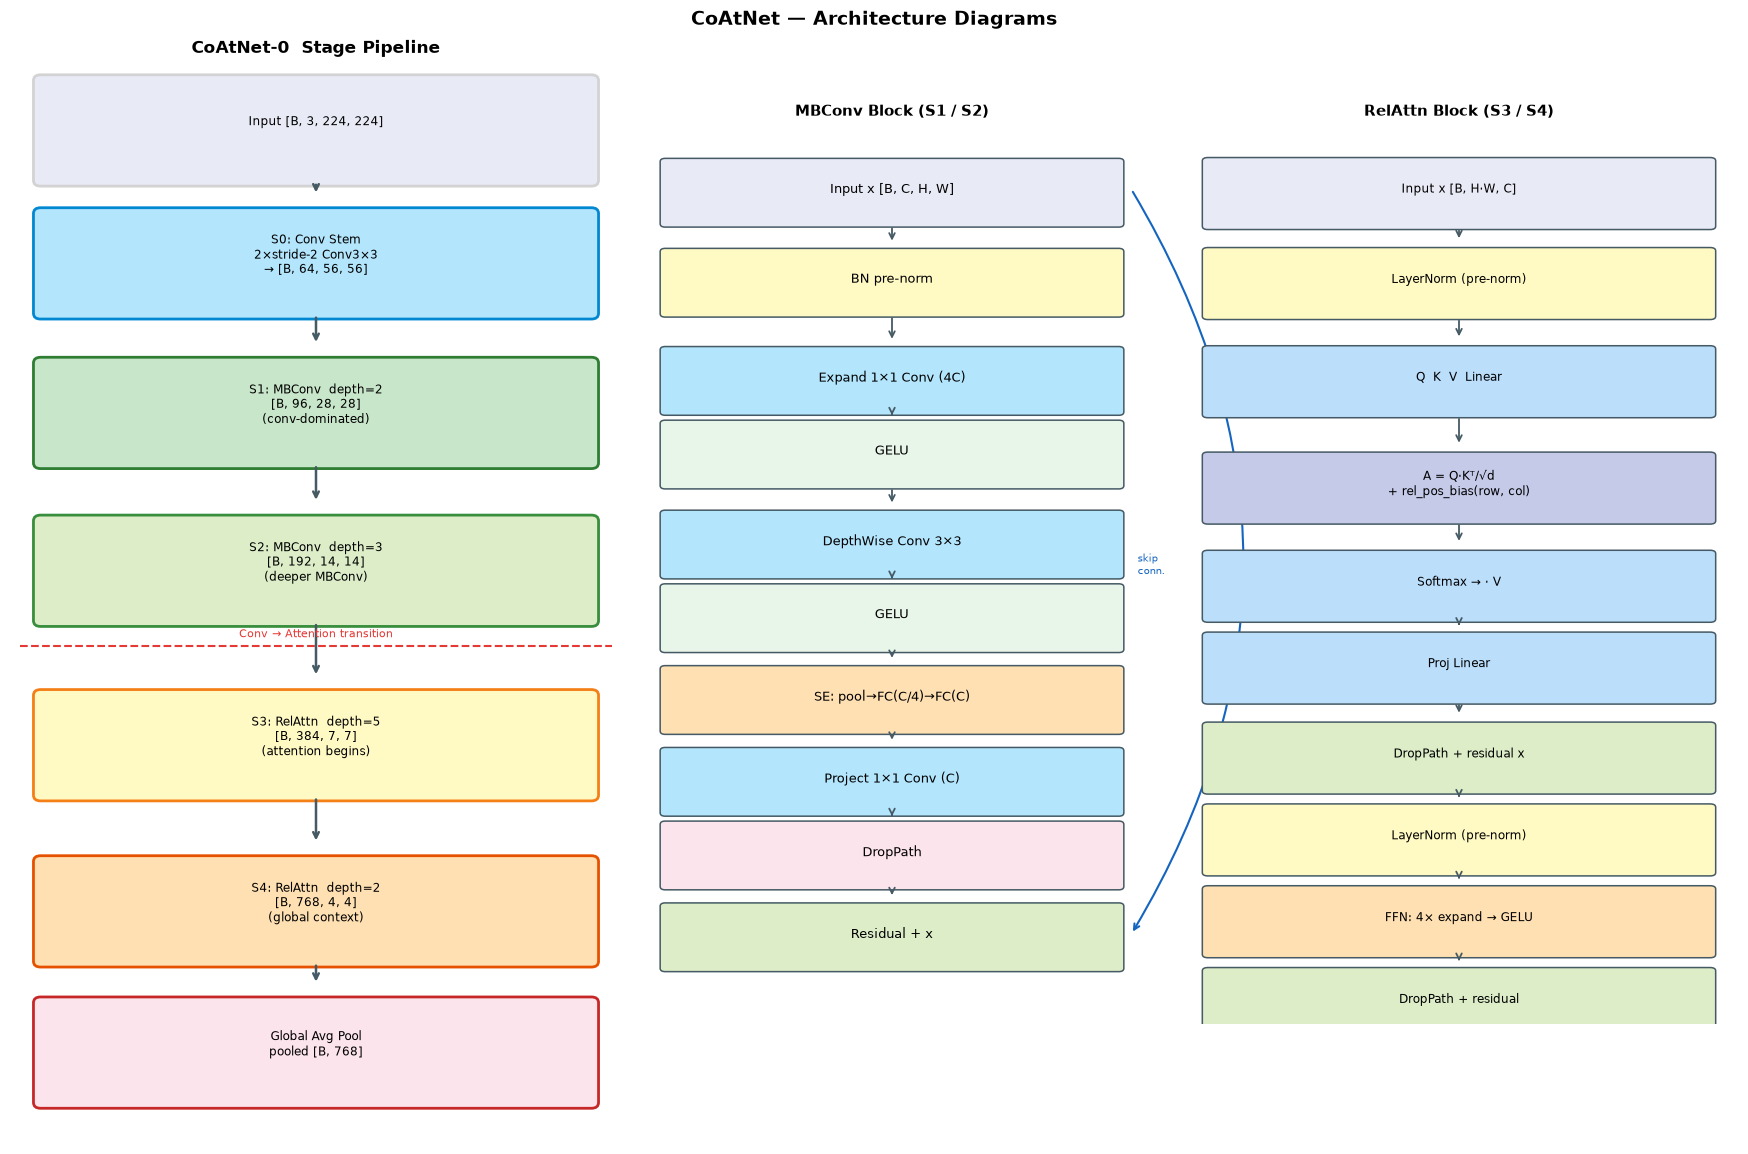

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

fig = plt.figure(figsize=(18, 12))

# ── Left panel: 5-stage pipeline ───────────────────────────────────────────
ax1 = fig.add_axes([0.02, 0.05, 0.34, 0.90])
ax1.set_xlim(0, 6)
ax1.set_ylim(0, 13)
ax1.axis('off')
ax1.set_title('CoAtNet-0  Stage Pipeline', fontsize=12, fontweight='bold', pad=8)

stages = [
    ('Input [B, 3, 224, 224]',            12.3, '#e8eaf6', 'lightgrey'),
    ('S0: Conv Stem\n2×stride-2 Conv3×3\n→ [B, 64, 56, 56]',    10.7, '#b3e5fc', '#0288d1'),
    ('S1: MBConv  depth=2\n[B, 96, 28, 28]\n(conv-dominated)',   8.9,  '#c8e6c9', '#2e7d32'),
    ('S2: MBConv  depth=3\n[B, 192, 14, 14]\n(deeper MBConv)',   7.0,  '#dcedc8', '#388e3c'),
    ('S3: RelAttn  depth=5\n[B, 384, 7, 7]\n(attention begins)', 4.9,  '#fff9c4', '#f57f17'),
    ('S4: RelAttn  depth=2\n[B, 768, 4, 4]\n(global context)',   2.9,  '#ffe0b2', '#e65100'),
    ('Global Avg Pool\npooled [B, 768]',  1.2,  '#fce4ec', '#c62828'),
]

for label, y, fc, ec in stages:
    box = FancyBboxPatch((0.3, y - 0.7), 5.4, 1.2,
                         boxstyle='round,pad=0.07', facecolor=fc, edgecolor=ec, linewidth=2.0)
    ax1.add_patch(box)
    ax1.text(3.0, y, label, ha='center', va='center', fontsize=8.5)

for i in range(len(stages) - 1):
    y1 = stages[i][1] - 0.72
    y2 = stages[i+1][1] + 0.72
    ax1.annotate('', xy=(3.0, y2), xytext=(3.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.8))

# Conv↔Attn boundary indicator
ax1.plot([0.1, 5.9], [6.0, 6.0], color='#e53935', lw=1.5, linestyle='--')
ax1.text(3.0, 6.1, 'Conv → Attention transition', ha='center', fontsize=8, color='#e53935')

# ── Middle panel: MBConv block ──────────────────────────────────────────────
ax2 = fig.add_axes([0.37, 0.15, 0.28, 0.75])
ax2.set_xlim(0, 4)
ax2.set_ylim(0, 11)
ax2.axis('off')
ax2.set_title('MBConv Block (S1 / S2)', fontsize=11, fontweight='bold', pad=6)

mbconv = [
    ('Input x [B, C, H, W]', 10.2, '#e8eaf6'),
    ('BN pre-norm', 9.1, '#fff9c4'),
    ('Expand 1×1 Conv (4C)', 7.9, '#b3e5fc'),
    ('GELU', 7.0, '#e8f5e9'),
    ('DepthWise Conv 3×3', 5.9, '#b3e5fc'),
    ('GELU', 5.0, '#e8f5e9'),
    ('SE: pool→FC(C/4)→FC(C)', 4.0, '#ffe0b2'),
    ('Project 1×1 Conv (C)', 3.0, '#b3e5fc'),
    ('DropPath', 2.1, '#fce4ec'),
    ('Residual + x', 1.1, '#dcedc8'),
]
for label, y, color in mbconv:
    box = FancyBboxPatch((0.2, y - 0.42), 3.6, 0.76,
                         boxstyle='round,pad=0.04', facecolor=color, edgecolor='#455a64', linewidth=1.1)
    ax2.add_patch(box)
    ax2.text(2.0, y, label, ha='center', va='center', fontsize=9)

for i in range(len(mbconv) - 1):
    y1 = mbconv[i][1] - 0.44
    y2 = mbconv[i+1][1] + 0.44
    ax2.annotate('', xy=(2.0, y2), xytext=(2.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.3))

# Residual skip arrow
ax2.annotate('', xy=(3.9, 1.1), xytext=(3.9, 10.2),
             arrowprops=dict(arrowstyle='->', color='#1565c0', lw=1.5,
                             connectionstyle='arc3,rad=-0.3'))
ax2.text(3.95, 5.5, 'skip\nconn.', ha='left', fontsize=7.5, color='#1565c0')

# ── Right panel: RelAttn block ─────────────────────────────────────────────
ax3 = fig.add_axes([0.67, 0.15, 0.31, 0.75])
ax3.set_xlim(0, 4)
ax3.set_ylim(0, 11)
ax3.axis('off')
ax3.set_title('RelAttn Block (S3 / S4)', fontsize=11, fontweight='bold', pad=6)

relattn = [
    ('Input x [B, H·W, C]', 10.2, '#e8eaf6'),
    ('LayerNorm (pre-norm)', 9.1,  '#fff9c4'),
    ('Q  K  V  Linear', 7.9, '#bbdefb'),
    ('A = Q·Kᵀ/√d\n+ rel_pos_bias(row, col)', 6.6, '#c5cae9'),
    ('Softmax → · V', 5.4, '#bbdefb'),
    ('Proj Linear', 4.4, '#bbdefb'),
    ('DropPath + residual x', 3.3, '#dcedc8'),
    ('LayerNorm (pre-norm)', 2.3, '#fff9c4'),
    ('FFN: 4× expand → GELU', 1.3, '#ffe0b2'),
    ('DropPath + residual', 0.3, '#dcedc8'),
]
for label, y, color in relattn:
    box = FancyBboxPatch((0.2, y - 0.45), 3.6, 0.80,
                         boxstyle='round,pad=0.04', facecolor=color, edgecolor='#455a64', linewidth=1.1)
    ax3.add_patch(box)
    ax3.text(2.0, y, label, ha='center', va='center', fontsize=8.8)

for i in range(len(relattn) - 1):
    y1 = relattn[i][1] - 0.47
    y2 = relattn[i+1][1] + 0.47
    ax3.annotate('', xy=(2.0, y2), xytext=(2.0, y1),
                 arrowprops=dict(arrowstyle='->', color='#455a64', lw=1.3))

plt.suptitle('CoAtNet — Architecture Diagrams', fontsize=14, fontweight='bold', y=0.995)

plt.show()

## 3. Key ideas

## Key Innovations

### 1. Why Stage Conv → Attention?

The paper analyses the *generalisation* and *capacity* of convolution vs. attention:

- **Convolution** has strong translation equivariance — a great prior for small data.
  Its receptive field grows slowly with depth, which is perfect for low-level edge/texture detection.
- **Self-attention** has global receptive field from layer 1 — powerful but data-hungry
  (needs large datasets to learn position relationships).

CoAtNet places convolution where its inductive bias is *helpful* (S0–S2, small feature maps
with local patterns) and attention where global context is *needed* (S3–S4, small spatial
size → low cost for global attention).

### 2. MBConv Block

Mobile Inverted Bottleneck from MobileNetV2 / EfficientNet, adapted with BN *before* the block:

$$x' = x + \text{Drop}\bigl(\text{Proj}_{1\times1}(\text{SE}(\text{DW}_{3\times3}(\sigma(\text{Expand}_{1\times1}(\text{BN}(x))))))\bigr)$$

- **BN pre-norm** (not post): normalises the input before expansion, which stabilises
  training when the first operation multiplies channels by 4.
- **SE (Squeeze-Excite):** global avg pool → FC(C→C/4) → ReLU → FC(C/4→C) → Sigmoid.
  Learns per-channel importance weights from the global spatial summary.
- **DropPath (Stochastic Depth):** each block is dropped with probability $p_i$
  linearly scheduled from $0$ to $\text{drop\_path\_rate}$:
$$p_i = \frac{i}{\text{total\_blocks}} \cdot \text{drop\_path\_rate}$$

### 3. Relative Multi-Head Self-Attention (RelAttn)

Standard MHSA attention logits:
$$A_{ij} = \frac{\mathbf{q}_i^\top \mathbf{k}_j}{\sqrt{d_k}}$$

CoAtNet adds a learnable 2D relative position bias:
$$A_{ij} = \frac{\mathbf{q}_i^\top \mathbf{k}_j}{\sqrt{d_k}} + B[\Delta r_{ij},\ \Delta c_{ij}]$$

where $B \in \mathbb{R}^{(2H_{\max}-1) \times (2W_{\max}-1)}$ per head, indexed by
$(\Delta r, \Delta c) = (r_i - r_j,\ c_i - c_j)$ clipped to $[-\text{max\_dist}, \text{max\_dist}]$.

### 4. Downsampling Strategy

Between stages: `MaxPool2d(2×2)` halves spatial resolution, then a `1×1 Conv` adjusts channels.
This separates the spatial downsampling (pooling — no learned parameters) from the
channel projection (conv — learned). Simpler and more stable than strided convolutions.

### 5. Model Variants

| Model | Depths [S1,S2,S3,S4] | Dims | Params |
|-------|---------------------|------|--------|
| coatnet_0 | [2,3,5,2] | [96,192,384,768] | ~25 M |
| coatnet_1 | [2,6,14,2] | [96,192,384,768] | ~42 M |
| coatnet_2 | [2,6,14,2] | [128,256,512,1024] | ~75 M |
| coatnet_3 | [2,6,14,2] | [192,384,768,1536] | ~168 M |
| coatnet_7 | [2,6,36,2] | [192,384,768,1536] | ~2.4 B |


## Code Walkthrough

### MBConv (`hale_core.nn.vision.hybrid.coatnet.MBConv`)

```python
class MBConv(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, expand=4, se_rd=0.25, drop_path=0.0):
        expand_ch = int(in_ch * expand)
        self.conv = nn.Sequential(
            nn.BatchNorm2d(in_ch),          # BN pre-norm
            nn.Conv2d(in_ch, expand_ch, 1), # 1×1 expand
            nn.GELU(),
            nn.Conv2d(expand_ch, expand_ch, 3, stride=stride, padding=1,
                      groups=expand_ch),    # depthwise 3×3
            nn.GELU(),
            SE(expand_ch, rd=int(in_ch * se_rd)),
            nn.Conv2d(expand_ch, out_ch, 1) # project back
        )
        self.use_res = (stride == 1 and in_ch == out_ch)
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        return x + self.drop_path(self.conv(x)) if self.use_res else self.conv(x)
```

### Relative Position Bias (`CoAtNetRelativeAttention`)

```python
class CoAtNetRelativeAttention(nn.Module):
    def __init__(self, dim, num_heads, max_dist):
        # One bias table per head: [2*max_dist-1, 2*max_dist-1]
        self.rel_bias = nn.Parameter(
            torch.zeros(num_heads, (2*max_dist-1)**2)
        )

    def forward(self, x):          # x: [B, H*W, C]
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        attn = q @ k.transpose(-2, -1) / self.scale

        # Build per-pair (row_diff, col_diff) index
        bias = self.rel_bias[:, self.rel_idx.view(-1)]   # [heads, H*W*H*W]
        bias = bias.view(self.num_heads, H*W, H*W)
        attn = attn + bias
        ...
```

### Backbone Construction

```python
# Build coatnet_0
from hale_core.nn.vision import build_vision_backbone
bb = build_vision_backbone('coatnet_0', img_size=224)

# Stages: [S0_stem, S1_mbconv, S2_mbconv, S3_relattn, S4_relattn]
# feature_maps returns S1..S4 outputs (4 multi-scale maps)
```


## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/hybrid/coatnet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>hybrid/coatnet.py</code></summary>

```text
CoAtNet — Marrying Convolution and Attention (Dai et al., 2021)
===============================================================

Reference: "CoAtNet: Marrying Convolution and Attention for All Data Sizes"
           https://arxiv.org/abs/2106.04803

Architecture overview
---------------------
CoAtNet is a hybrid architecture that uses convolution in early stages
(where local patterns matter) and self-attention in later stages
(where global context matters). This staged hybrid outperforms pure
ViT on small/medium data while matching it on large data.

Stage layout (5 stages total):
  S0 (Conv Stem): 2× Conv2d stride-2, pure convolution, H→H/4
  S1 (MBConv):    Mobile Inverted Bottleneck blocks, H/4→H/8
  S2 (MBConv):    Wider/deeper MBConv, H/8→H/16
  S3 (RelAttn):   Transformer blocks with relative position bias, H/16→H/32
  S4 (RelAttn):   Deeper transformer, H/32 (final)

Feature maps for FPN come from S1..S4 (4 multi-scale outputs).

Key design decisions
--------------------
**MBConv block** (Mobile Inverted Bottleneck):
  - Pre-BatchNorm: BN is applied BEFORE the block (normalise input),
    unlike standard post-norm in the original MobileNetV2.
  - Depthwise separable: expand 1×1 → depthwise 3×3 → SE → project 1×1
  - Squeeze-Excitation (SE): channel attention using global avg pool + 2-FC.
  - Residual skip only when input/output dims match.

**Relative Multi-Head Attention block**:
  - Pre-LayerNorm for attention AND FFN sublayers.
  - Relative position bias: a table of shape [2*Hmax-1, 2*Wmax-1] is learned
    for each head; biases are added to attention logits based on (row_diff, col_diff).
  - Bias indices are clipped so the table covers all positions up to max_img_size.
  - Output: standard Q·K^T/sqrt(d) + rel_bias, then V aggregation.

**Downsampling** between stages:
  - MaxPool2d(2×2) for spatial halving.
  - 1×1 Conv to change channel dimension.

BackboneOutput
--------------
  pooled_output : [B, dims[-1]]                  — global average pool of S4
  feature_maps  : [S1, S2, S3, S4]               — 4 multi-scale spatial maps
  patch_tokens  : None                           — not applicable
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `hybrid/coatnet.py`, definition by definition

In [5]:
def _trunc_normal_(t: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    with torch.no_grad():
        return t.normal_(0, std).clamp_(-2 * std, 2 * std)

**`DropPath`** - Stochastic depth — drop entire residual branch per sample.

In [6]:
class DropPath(nn.Module):
    """Stochastic depth — drop entire residual branch per sample."""

    def __init__(self, drop_prob: float = 0.0) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0:
            return x
        keep = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.rand(shape, device=x.device, dtype=x.dtype).floor_() + keep
        return x.div(keep) * noise

**`SqueezeExcitation`** - Channel-wise gating: global avg pool → 2-FC → sigmoid scale.

In [7]:
class SqueezeExcitation(nn.Module):
    """Channel-wise gating: global avg pool → 2-FC → sigmoid scale.

    Args:
        channels:    Input/output channel count.
        rd_ratio:    Reduction ratio for bottleneck (default 0.25 = 4×).
        activation:  Activation between FC layers.
    """

    def __init__(
        self,
        channels: int,
        rd_ratio: float = 0.25,
        activation: nn.Module = None,
    ) -> None:
        super().__init__()
        rd = max(1, int(channels * rd_ratio))
        self.fc1 = nn.Linear(channels, rd, bias=True)
        self.fc2 = nn.Linear(rd, channels, bias=True)
        self.act = activation or nn.SiLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B, C, H, W] → scale [B, C, 1, 1] applied to x."""
        s = x.mean(dim=(2, 3))          # Global avg pool: [B, C]
        s = self.act(self.fc1(s))       # Bottleneck
        s = self.fc2(s).sigmoid()       # Gate in [0, 1]
        return x * s[:, :, None, None]  # Scale channels

**`MBConvBlock`** - Mobile Inverted Bottleneck Convolution block.

In [8]:
class MBConvBlock(nn.Module):
    """Mobile Inverted Bottleneck Convolution block.

    Used in S1 and S2 of CoAtNet. Pattern:
      [input]
        ↓ (BatchNorm — pre-norm applied to input)
        ↓ expand 1×1 conv (expand_ratio × C channels)
        ↓ depthwise 3×3 conv (groups=out_channels for true depthwise)
        ↓ Squeeze-Excitation
        ↓ project 1×1 conv (back to out_channels)
        ↓ (+ residual if in_channels == out_channels and stride==1)

    Args:
        in_ch:        Input channels.
        out_ch:       Output channels.
        stride:       Spatial stride (1 or 2).
        expand_ratio: Expansion multiplier for intermediate channels.
        se_ratio:     SE reduction ratio.
        drop_path:    Stochastic depth rate.
    """

    def __init__(
        self,
        in_ch: int,
        out_ch: int,
        stride: int = 1,
        expand_ratio: int = 4,
        se_ratio: float = 0.25,
        drop_path: float = 0.0,
    ) -> None:
        super().__init__()
        mid_ch = in_ch * expand_ratio
        self.use_residual = (in_ch == out_ch and stride == 1)

        # Pre-BatchNorm normalises the input before the block
        self.pre_norm = nn.BatchNorm2d(in_ch)

        self.expand = nn.Conv2d(in_ch, mid_ch, 1, bias=False)
        self.expand_act = nn.SiLU()

        # Depthwise 3×3 — groups=mid_ch means each channel has its own filter
        self.dw_conv = nn.Conv2d(
            mid_ch, mid_ch, 3, stride=stride, padding=1, groups=mid_ch, bias=False
        )
        self.dw_bn = nn.BatchNorm2d(mid_ch)
        self.dw_act = nn.SiLU()

        self.se = SqueezeExcitation(mid_ch, rd_ratio=se_ratio / expand_ratio)

        self.project = nn.Conv2d(mid_ch, out_ch, 1, bias=False)
        self.project_bn = nn.BatchNorm2d(out_ch)

        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x
        x = self.pre_norm(x)
        x = self.expand_act(self.expand(x))
        x = self.dw_act(self.dw_bn(self.dw_conv(x)))
        x = self.se(x)
        x = self.project_bn(self.project(x))
        if self.use_residual:
            x = residual + self.drop_path(x)
        return x

**`RelativePositionBias`** - Learnable relative position bias indexed by (row_diff, col_diff).

In [9]:
class RelativePositionBias(nn.Module):
    """Learnable relative position bias indexed by (row_diff, col_diff).

    Table size: (2*max_dist-1) × (2*max_dist-1) per head.
    At each attention step, bias is indexed by the pair-wise position
    differences (clipped to [-max_dist+1, max_dist-1]).

    Args:
        num_heads: Number of attention heads.
        max_dist:  Maximum position difference to represent (default 64).
    """

    def __init__(self, num_heads: int, max_dist: int = 64) -> None:
        super().__init__()
        self.num_heads = num_heads
        self.max_dist = max_dist
        table_size = (2 * max_dist - 1) ** 2
        self.table = nn.Parameter(torch.zeros(table_size, num_heads))
        _trunc_normal_(self.table, std=0.02)

        # Cache the index lookup for a given H×W grid
        self._cached_hw: Optional[tuple] = None
        self._cached_idx: Optional[torch.Tensor] = None

    def _build_index(self, H: int, W: int) -> torch.Tensor:
        """Precompute flat indices into the bias table for an H×W grid."""
        coords = torch.stack(
            torch.meshgrid(torch.arange(H), torch.arange(W), indexing="ij")
        ).flatten(1)  # [2, H*W]
        # Pairwise differences
        rel_h = coords[0][:, None] - coords[0][None, :]  # [H*W, H*W]
        rel_w = coords[1][:, None] - coords[1][None, :]
        # Clip to [-max_dist+1, max_dist-1]
        md = self.max_dist - 1
        rel_h = rel_h.clamp(-md, md) + md
        rel_w = rel_w.clamp(-md, md) + md
        # Map to flat index into table of shape [2*max_dist-1, 2*max_dist-1]
        idx = rel_h * (2 * self.max_dist - 1) + rel_w  # [H*W, H*W]
        return idx

    def forward(self, H: int, W: int) -> torch.Tensor:
        """Return [num_heads, H*W, H*W] bias to add to attention logits."""
        if self._cached_hw != (H, W):
            self._cached_idx = self._build_index(H, W).to(self.table.device)
            self._cached_hw = (H, W)
        idx = self._cached_idx  # [H*W, H*W]
        N = H * W
        # Index table [table_size, num_heads] → [H*W, H*W, num_heads]
        bias = self.table[idx.view(-1)].view(N, N, self.num_heads)
        return bias.permute(2, 0, 1)  # [num_heads, H*W, H*W]

**`RelativeAttentionBlock`** - Transformer block with relative position bias (used in S3, S4).

In [10]:
class RelativeAttentionBlock(nn.Module):
    """Transformer block with relative position bias (used in S3, S4).

    Layout (pre-norm):
      x → LN → MHSA → + residual → LN → FFN → + residual

    Relative position bias is added to QK^T before softmax.

    Args:
        dim:       Channel dimension.
        num_heads: Attention heads.
        mlp_ratio: FFN hidden expand ratio.
        drop_path: Stochastic depth rate.
        max_dist:  Maximum relative position distance for bias table.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        drop_path: float = 0.0,
        max_dist: int = 64,
    ) -> None:
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5

        self.norm1 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

        self.norm2 = nn.LayerNorm(dim)
        mlp_dim = int(dim * mlp_ratio)
        self.ffn = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, dim),
        )

        self.rel_bias = RelativePositionBias(num_heads, max_dist=max_dist)
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

    def _attn(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        """Full self-attention with relative position bias over H×W spatial grid."""
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)  # [B, heads, N, d]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        # Add relative position bias [heads, N, N]
        attn = attn + self.rel_bias(H, W).unsqueeze(0)
        attn = F.softmax(attn, dim=-1)

        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        return self.proj(out)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        """
        Args:
            x: [B, H*W, C]  — flattened spatial tokens
        Returns:
            x: [B, H*W, C]
        """
        x = x + self.drop_path(self._attn(self.norm1(x), H, W))
        x = x + self.drop_path(self.ffn(self.norm2(x)))
        return x

**`CoAtNetConvStage`** - Sequence of MBConv blocks with optional downsampling at the start.

In [11]:
class CoAtNetConvStage(nn.Module):
    """Sequence of MBConv blocks with optional downsampling at the start.

    Args:
        in_ch:    Input channels.
        out_ch:   Output channels.
        depth:    Number of MBConv blocks.
        stride:   Spatial stride for the first block (1 = no downscale).
        drop_path_rates: Per-block stochastic depth rates.
    """

    def __init__(
        self,
        in_ch: int,
        out_ch: int,
        depth: int,
        stride: int = 2,
        drop_path_rates: Optional[list] = None,
    ) -> None:
        super().__init__()
        rates = drop_path_rates or [0.0] * depth
        # First block handles channel change + optional stride
        blocks = [MBConvBlock(in_ch, out_ch, stride=stride, drop_path=rates[0])]
        for i in range(1, depth):
            blocks.append(MBConvBlock(out_ch, out_ch, stride=1, drop_path=rates[i]))
        self.blocks = nn.Sequential(*blocks)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.blocks(x)

**`CoAtNetAttnStage`** - Sequence of Transformer blocks with optional spatial downsampling.

In [12]:
class CoAtNetAttnStage(nn.Module):
    """Sequence of Transformer blocks with optional spatial downsampling.

    Downsampling: MaxPool2d(2) + 1×1 Conv before the transformer blocks.

    Args:
        in_ch:    Input channels.
        out_ch:   Output channels.
        depth:    Number of transformer blocks.
        num_heads: Attention heads.
        stride:   Spatial stride (2 = halve resolution with pool+conv).
        drop_path_rates: Per-block stochastic depth rates.
    """

    def __init__(
        self,
        in_ch: int,
        out_ch: int,
        depth: int,
        num_heads: int,
        stride: int = 2,
        drop_path_rates: Optional[list] = None,
    ) -> None:
        super().__init__()
        rates = drop_path_rates or [0.0] * depth

        # Downsampling: pool for spatial halving, 1×1 conv for channel change
        if stride == 2:
            self.downsample = nn.Sequential(
                nn.MaxPool2d(kernel_size=2, stride=2),
                nn.Conv2d(in_ch, out_ch, 1, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.downsample = nn.Conv2d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()

        self.blocks = nn.ModuleList([
            RelativeAttentionBlock(out_ch, num_heads, drop_path=rates[i])
            for i in range(depth)
        ])
        self.norm = nn.LayerNorm(out_ch)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: [B, C, H, W] → [B, C', H', W']"""
        x = self.downsample(x)
        B, C, H, W = x.shape
        # Flatten spatial dims for transformer: [B, H*W, C]
        tokens = x.permute(0, 2, 3, 1).reshape(B, H * W, C)
        for blk in self.blocks:
            tokens = blk(tokens, H, W)
        tokens = self.norm(tokens)
        # Restore spatial layout: [B, C, H, W]
        return tokens.reshape(B, H, W, C).permute(0, 3, 1, 2).contiguous()

**`CoAtNetBackbone`** - CoAtNet vision backbone.

In [13]:
class CoAtNetBackbone(BaseVisionBackbone):
    """CoAtNet vision backbone.

    5-stage architecture: Conv Stem + 2 MBConv stages + 2 Attention stages.

    Args:
        dims:    Channel counts for [stem, S1, S2, S3, S4].
        depths:  Block counts for [stem, S1, S2, S3, S4].
                 Stem depth is number of conv layers (typically 2).
        num_heads_attn: Attention heads for S3 and S4.
        drop_path_rate: Total stochastic depth rate.
        **base_kwargs: Passed to BaseVisionBackbone.
    """

    def __init__(
        self,
        dims: list = None,
        depths: list = None,
        num_heads_attn: int = 8,
        drop_path_rate: float = 0.2,
        **base_kwargs,
    ) -> None:
        super().__init__(**base_kwargs)
        dims = dims or [64, 96, 192, 384, 768]
        depths = depths or [2, 3, 5, 2, 2]

        # Class-level attributes for base __repr__
        self.__class__.feature_dims = dims[1:]       # S1..S4 channel counts
        self.__class__.embed_dim = dims[-1]

        # Distribute drop_path evenly over all non-stem blocks
        total = sum(depths[1:])
        dp_rates = [x.item() for x in torch.linspace(0, drop_path_rate, total)]
        idx = 0

        # S0: Conv stem — two stride-2 convolutions  (input H → H/4)
        self.stem = nn.Sequential(
            nn.Conv2d(self.in_chans, dims[0], 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(dims[0]),
            nn.GELU(),
            nn.Conv2d(dims[0], dims[0], 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(dims[0]),
            nn.GELU(),
        )

        def _take(n: int) -> list:
            nonlocal idx
            r = dp_rates[idx: idx + n]
            idx += n
            return r

        # S1: MBConv blocks, stride-2 → H/8
        self.s1 = CoAtNetConvStage(
            dims[0], dims[1], depths[1], stride=2, drop_path_rates=_take(depths[1])
        )
        # S2: MBConv blocks, stride-2 → H/16
        self.s2 = CoAtNetConvStage(
            dims[1], dims[2], depths[2], stride=2, drop_path_rates=_take(depths[2])
        )
        # S3: Attention blocks, stride-2 → H/32
        heads3 = max(1, dims[3] // 64)  # ~1 head per 64 dim
        self.s3 = CoAtNetAttnStage(
            dims[2], dims[3], depths[3], num_heads=heads3, stride=2,
            drop_path_rates=_take(depths[3])
        )
        # S4: Attention blocks, stride-1 (maintain resolution)
        heads4 = max(1, dims[4] // 64)
        self.s4 = CoAtNetAttnStage(
            dims[3], dims[4], depths[4], num_heads=heads4, stride=1,
            drop_path_rates=_take(depths[4])
        )

        self.drop = nn.Dropout(self.drop_rate)
        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                _trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem (stage -1) + conv/attn stages 0..stage."""
        all_stages = [self.stem, self.s1, self.s2, self.s3, self.s4]
        for i in range(min(stage + 2, len(all_stages))):  # +2: stem counts as stage -1
            for p in all_stages[i].parameters():
                p.requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """
        Args:
            x: [B, 3, H, W]
        Returns:
            BackboneOutput with 4 feature maps (S1..S4) and pooled_output
        """
        x = self.stem(x)          # [B, dims[0], H/4, W/4]

        s1 = self.s1(x)           # [B, dims[1], H/8,  W/8]
        s2 = self.s2(s1)          # [B, dims[2], H/16, W/16]
        s3 = self.s3(s2)          # [B, dims[3], H/32, W/32]
        s4 = self.s4(s3)          # [B, dims[4], H/32, W/32] (stride-1)

        # Global average pool over final spatial map for pooled embedding
        pooled = s4.mean(dim=(2, 3))  # [B, dims[4]]
        pooled = self.drop(pooled)

        feature_maps = [s1, s2, s3, s4]
        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
        )

**`CoAtNet0`** - CoAtNet-0: ~25M params. Fastest in the CoAtNet family.

In [14]:
@register_vision_backbone("coatnet_0")
class CoAtNet0(CoAtNetBackbone):
    """CoAtNet-0: ~25M params. Fastest in the CoAtNet family."""
    arch_name = "coatnet_0"
    embed_dim = 768

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dims", [64, 96, 192, 384, 768])
        kwargs.setdefault("depths", [2, 3, 5, 2, 2])
        super().__init__(**kwargs)

**`CoAtNet1`** - CoAtNet-1: ~42M params. More blocks for better feature quality.

In [15]:
@register_vision_backbone("coatnet_1")
class CoAtNet1(CoAtNetBackbone):
    """CoAtNet-1: ~42M params. More blocks for better feature quality."""
    arch_name = "coatnet_1"
    embed_dim = 768

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dims", [64, 96, 192, 384, 768])
        kwargs.setdefault("depths", [2, 6, 14, 2, 2])
        super().__init__(**kwargs)

**`CoAtNet2`** - CoAtNet-2: ~75M params. Wider with 128-dim stem.

In [16]:
@register_vision_backbone("coatnet_2")
class CoAtNet2(CoAtNetBackbone):
    """CoAtNet-2: ~75M params. Wider with 128-dim stem."""
    arch_name = "coatnet_2"
    embed_dim = 1024

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dims", [128, 128, 256, 512, 1024])
        kwargs.setdefault("depths", [2, 6, 14, 2, 2])
        super().__init__(**kwargs)

**`CoAtNet3`** - CoAtNet-3: ~168M params. Large-scale model for high accuracy.

In [17]:
@register_vision_backbone("coatnet_3")
class CoAtNet3(CoAtNetBackbone):
    """CoAtNet-3: ~168M params. Large-scale model for high accuracy."""
    arch_name = "coatnet_3"
    embed_dim = 1536

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dims", [192, 192, 384, 768, 1536])
        kwargs.setdefault("depths", [2, 6, 14, 2, 2])
        super().__init__(**kwargs)

**`CoAtNet7`** - CoAtNet-7: ~2.4B params. Giant model matching ViT-22B scale.

In [18]:
@register_vision_backbone("coatnet_7")
class CoAtNet7(CoAtNetBackbone):
    """CoAtNet-7: ~2.4B params. Giant model matching ViT-22B scale."""
    arch_name = "coatnet_7"
    embed_dim = 1536

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("dims", [192, 192, 384, 768, 1536])
        kwargs.setdefault("depths", [2, 12, 28, 2, 2])
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [19]:
DEMOS = {"coatnet_0": 25.0}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['coatnet_0', 'coatnet_1', 'coatnet_2', 'coatnet_3', 'coatnet_7']



coatnet_0  (CoAtNet0)
  pooled_output : (2, 768)   embed_dim = 768
  feature_map 0: (2, 96, 28, 28)   stride 8
  feature_map 1: (2, 192, 14, 14)   stride 16
  feature_map 2: (2, 384, 7, 7)   stride 32
  feature_map 3: (2, 768, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** The feature maps come out at strides 8/16/32/32 instead of the paper's 4/8/16/32 (one stride-2 too early and none in the last stage), and the parameter count is ~14 % below the paper.

In [20]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
coatnet_0                20.61M     21.38M    25.0M    0.86  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [21]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

coatnet_0: loss 10.1217 | 170/170 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [22]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

coatnet_0: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

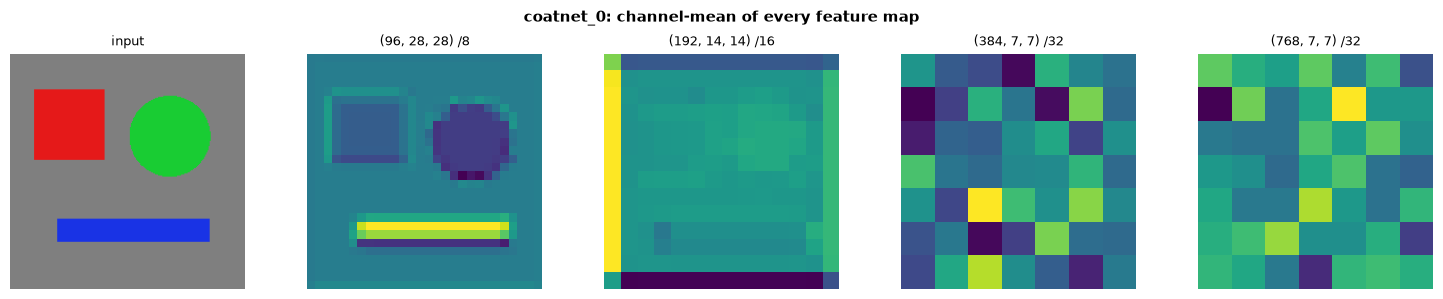

In [23]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [24]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [25]:
import sys
import torch

backbone = build_vision_backbone('coatnet_0', img_size=224)
backbone.eval()

print(f'Model: coatnet_0')
print(f'Parameters : {backbone.num_parameters():,}')
print(f'Embed dim  : {backbone.embed_dim}')
print(f'Feature dims: {backbone.feature_dims}')
print()

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print('BackboneOutput:')
print(f'  pooled_output : {tuple(out.pooled_output.shape)}')
print(f'  feature_maps  : {[tuple(fm.shape) for fm in out.feature_maps]}')

# Count params per stage
print('\nParameter counts per stage:')
for name, module in [('stem', backbone.stem),
                     ('s1',   backbone.s1),
                     ('s2',   backbone.s2),
                     ('s3',   backbone.s3),
                     ('s4',   backbone.s4)]:
    n = sum(p.numel() for p in module.parameters())
    print(f'  {name:6s}: {n:>10,} params')

# Demonstrate stochastic depth — drop probs increase with depth
print('\nDropPath rates (first 5 blocks):')
cnt = 0
for stage_name in ['s1', 's2', 's3', 's4']:
    stage = getattr(backbone, stage_name)
    for blk in stage.children():
        if hasattr(blk, 'drop_path') and hasattr(blk.drop_path, 'drop_prob'):
            print(f'  block {cnt:02d}: drop_prob={blk.drop_path.drop_prob:.4f}')
            cnt += 1
            if cnt >= 5:
                break
    if cnt >= 5:
        break

Model: coatnet_0
Parameters : 20,611,708
Embed dim  : 768
Feature dims: [96, 192, 384, 768]

BackboneOutput:
  pooled_output : (1, 768)
  feature_maps  : [(1, 96, 28, 28), (1, 192, 14, 14), (1, 384, 7, 7), (1, 768, 7, 7)]

Parameter counts per stage:
  stem  :     38,848 params
  s1    :    246,912 params
  s2    :  1,648,920 params
  s3    :  3,817,740 params
  s4    : 14,859,288 params

DropPath rates (first 5 blocks):


## Paper Citation & Related Work

### Primary Reference

> Z. Dai, H. Liu, Q. V. Le, and M. Tan,
> "CoAtNet: Marrying Convolution and Attention for All Data Sizes,"
> in *Advances in Neural Information Processing Systems (NeurIPS)*, 2021, vol. 34, pp. 3965–3977.
> **arXiv:** https://arxiv.org/abs/2106.04803

### Related Work

| Model | Key Idea | Reference |
|-------|----------|----------|
| MobileNetV2 | Inverted residual + depthwise sep. conv | Sandler et al., CVPR 2018 |
| EfficientNet | NAS-optimised MBConv scaling | Tan & Le, ICML 2019 |
| ViT | Pure patch self-attention | Dosovitskiy et al., ICLR 2021 |
| CvT | Conv-Attention hybrid | Wu et al., ICCV 2021 |
| MaxViT | Multi-axis block + grid attn | Tu et al., ECCV 2022 |
| ConvNeXt V2 | Pure conv with global response norm | Woo et al., CVPR 2023 |

### Key Results from Paper

- **CoAtNet-3** achieves **88.52%** ImageNet top-1 without extra data
- **CoAtNet-4** reaches **89.11%** when pretrained on ImageNet-21K
- **CoAtNet-7** achieves **90.88%** with JFT-3B pretraining
- Outperforms ViT-G and EfficientNet-X at equal parameter counts on all dataset sizes
- Key ablation: removing the conv stages (pure attention) drops accuracy by ~1.5% on ImageNet-1K
